# 6 · Your own neural network as the model

abbot's default model is a Gaussian process. When you'd rather use a neural
network (lots of runs, inputs that aren't a handful of numbers, a network you've
already designed), `abbot.nn` wraps it so every policy can use it. You write the
network; abbot scales the inputs and outputs, trains it, starts each fit from the
last one, and turns it into a model with uncertainty.

`abbot.nn` is **experimental**: its options and defaults may change.

In [1]:
import torch
from abbot import BAXPolicy, Campaign, ContinuousDomain, LevelSet, OutputSpec, ProblemSpec
from abbot.nn import DeepKernelConstructor, MCDropoutConstructor, NetEnsembleConstructor
torch.manual_seed(0)

### The problem
Two knobs and one measured property. We want the region where the property is at
least 0.5, which here is two separate patches.

In [2]:
spec = ProblemSpec(
    domain=[
        ContinuousDomain(name="x1", lower=0.0, upper=1.0),
        ContinuousDomain(name="x2", lower=0.0, upper=1.0),
    ],
    outputs=[OutputSpec(name="signal", direction="OBSERVE")],
)

def signal(x1, x2):
    a = torch.exp(-((x1 - 0.25) ** 2 + (x2 - 0.7) ** 2) / 0.02)
    b = torch.exp(-((x1 - 0.75) ** 2 + (x2 - 0.3) ** 2) / 0.03)
    return a + 0.8 * b

class Experiment:
    @staticmethod
    def run(design):
        x1, x2 = torch.tensor(design["x1"]), torch.tensor(design["x2"])
        return [float(signal(x1, x2))]

goal = LevelSet(threshold=0.5, output="signal")

### Your network
`make_net(d_in, d_out)` returns any `torch.nn.Module` from `(N, d_in)` to
`(N, d_out)`. abbot calls it once per ensemble member, converts it to float64 and
puts it on the campaign's device. Inputs arrive scaled to [0, 1] when you pass
`bounds`.

In [3]:
def make_net(d_in, d_out):
    return torch.nn.Sequential(
        torch.nn.Linear(d_in, 64), torch.nn.ReLU(),
        torch.nn.Linear(64, 64), torch.nn.ReLU(),
        torch.nn.Linear(64, d_out),
    )

### An ensemble, in a campaign
`NetEnsembleConstructor` trains five copies from different starting weights; where
they disagree, the model is unsure. It plugs into `Campaign` like any model. Here
SwitchBAX measures inside the region the model currently predicts, and when there's
nothing new there, asks where a run would say most about the region (InfoBAX,
which updates the network by fine-tuning a copy on each guess).

In [4]:
model = NetEnsembleConstructor(make_net, n_members=5, bounds=spec.bounds_tensor())
policy = BAXPolicy(goal, "SwitchBAX", n_candidates=400)
campaign = Campaign(spec, policy, model)
for _ in range(25):
    campaign.step(Experiment)
print(len(campaign.history), "runs")

25 runs


### How well does it know the region?
Compare the region the model predicts (on its mean) with the true one, over the
candidate grid. Jaccard is the overlap divided by the union: 1 is a perfect match.

In [5]:
grid = policy.candidate_grid(spec)
truth = set(goal.bind(spec).identify_subspace(signal(grid[:, 0], grid[:, 1]).unsqueeze(-1)))

def jaccard(campaign):
    with torch.no_grad():
        mean = campaign.current_model().posterior(grid).mean
    found = set(goal.bind(spec).identify_subspace(mean))
    return len(found & truth) / len(found | truth)

print(f"Jaccard: {jaccard(campaign):.2f}")

Jaccard: 0.56


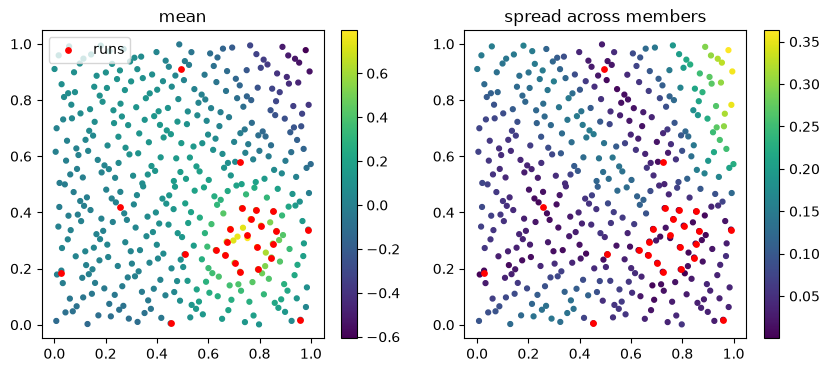

In [6]:
import matplotlib.pyplot as plt

with torch.no_grad():
    post = campaign.current_model().posterior(grid)
runs = campaign.history.designs
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, values, title in [(ax[0], post.mean[:, 0], "mean"), (ax[1], post.variance[:, 0].sqrt(), "spread across members")]:
    s = a.scatter(grid[:, 0], grid[:, 1], c=values, s=12)
    a.scatter(runs[:, 0], runs[:, 1], c="red", s=15, label="runs")
    a.set_title(title); fig.colorbar(s, ax=a)
ax[0].legend()
plt.show()

### Other ways to get uncertainty
Swap the constructor; nothing else changes.

- **MC dropout:** one network with `Dropout` layers, sampled with dropout on.
  Each sample is one dropout mask, shared by every design, so a sample is one
  function.
- **Deep kernel:** the network maps designs to a few features and a GP works on
  them. It's a GP, so it gives calibrated uncertainty and works with every policy.

For comparison, the default GP runs on the same budget. On a smooth problem with a
few dozen runs, like this one, expect the GP to do better: networks earn their
place with many runs, many inputs, or inputs that aren't numbers.

In [7]:
def make_dropout_net(d_in, d_out):
    return torch.nn.Sequential(
        torch.nn.Linear(d_in, 64), torch.nn.ReLU(), torch.nn.Dropout(0.1),
        torch.nn.Linear(64, 64), torch.nn.ReLU(), torch.nn.Dropout(0.1),
        torch.nn.Linear(64, d_out),
    )

for name, model in [
    ("MC dropout", MCDropoutConstructor(make_dropout_net, n_samples=16, bounds=spec.bounds_tensor())),
    ("deep kernel", DeepKernelConstructor(make_net, n_features=4, bounds=spec.bounds_tensor())),
    ("GP (the default)", None),
]:
    torch.manual_seed(0)
    policy = BAXPolicy(goal, "SwitchBAX", n_candidates=400)
    other = Campaign(spec, policy, model)
    for _ in range(25):
        other.step(Experiment)
    print(f"{name}: Jaccard {jaccard(other):.2f}")

MC dropout: Jaccard 0.44


deep kernel: Jaccard 0.30


GP (the default): Jaccard 0.56


### Training: yours to tune
The defaults are a starting point, checked only on small problems like this one.

- `epochs` (first fit), `warm_epochs` (later fits, starting from the last weights;
  `None` starts fresh each time), `refit_epochs` (InfoBAX's fine-tunes);
- `lr`, `weight_decay`, `batch_size` for the default trainer (Adam on the squared
  error), or `train=` for your own: `train(net, X, Y, epochs)`, where `net` maps raw
  designs to standardized outputs and `Y` has NaN where a run didn't measure an
  output;
- `noise=` when you know the measurement noise (a variance per output).

In [8]:
def train(net, X, Y, epochs):
    opt = torch.optim.AdamW(net.parameters(), lr=3e-3, weight_decay=1e-4)
    seen = ~Y.isnan()
    for _ in range(epochs):
        opt.zero_grad()
        loss = torch.nn.functional.huber_loss(net(X)[seen], Y[seen])
        loss.backward()
        opt.step()

model = NetEnsembleConstructor(make_net, bounds=spec.bounds_tensor(), train=train, epochs=800)

### Inputs that aren't numbers
When a design is a structure (a molecule, a crystal), give each one an index and
let `featurize` turn indices into whatever your network takes. abbot passes the raw
designs to `featurize` and doesn't scale them.

In [9]:
from abbot import IntegerDomain

structures = torch.randn(50, 8, dtype=torch.double)   # stand-in descriptors, one row per structure
indexed = ProblemSpec(
    domain=[IntegerDomain(name="structure", lower=0, upper=49)],
    outputs=[OutputSpec(name="signal", direction="OBSERVE")],
)

def featurize(X):                                     # (N, 1) indices -> (N, 8) inputs
    return structures[X[:, 0].long()]

model = NetEnsembleConstructor(lambda d_in, d_out: make_net(8, d_out), featurize=featurize)

### When a network helps
A standard GP assumes the output varies about equally fast everywhere, with one
lengthscale per input. Here the output **jumps** by 3 across a wavy boundary in
`x1`, `x2`, and a small **bump** in `x1`, `x3` sits on the high side. The goal is
the high side near the top of the bump (y ≥ 3.4), about 3% of the space: finding
it needs both the jump and the bump.

In [10]:
import logging
import math
import warnings

# Quiet for a short output: the policy says, while the model predicts no target
# anywhere, that it explores by uncertainty instead; GPyTorch notes numerical jitter.
logging.getLogger("abbot").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*added jitter.*")

jump_spec = ProblemSpec(
    domain=[ContinuousDomain(name=n, lower=0.0, upper=1.0) for n in ("x1", "x2", "x3")],
    outputs=[OutputSpec(name="y", direction="OBSERVE")],
)

def jump_and_bump(X):
    x1, x2, x3 = X[..., 0], X[..., 1], X[..., 2]
    high = (x2 > 0.5 + 0.2 * torch.sin(2 * math.pi * x1)).double()
    return 3 * high + 0.8 * torch.exp(-((x1 - 0.3) ** 2 + (x3 - 0.6) ** 2) / 0.04)

class JumpExperiment:
    @staticmethod
    def run(design):
        x = torch.tensor([design["x1"], design["x2"], design["x3"]], dtype=torch.double)
        return [float(jump_and_bump(x))]

jump_goal = LevelSet(threshold=3.4, output="y")

def wider_net(d_in, d_out):
    return torch.nn.Sequential(
        torch.nn.Linear(d_in, 128), torch.nn.ReLU(),
        torch.nn.Linear(128, 128), torch.nn.ReLU(),
        torch.nn.Linear(128, d_out),
    )

found = {}
for name, model in [
    ("GP (the default)", None),
    ("ensemble", NetEnsembleConstructor(wider_net, bounds=jump_spec.bounds_tensor())),
]:
    torch.manual_seed(0)
    policy = BAXPolicy(jump_goal, "InfoBAX", n_candidates=1000)
    found[name] = Campaign(jump_spec, policy, model)
    for _ in range(80):
        found[name].step(JumpExperiment)
    grid = policy.candidate_grid(jump_spec)
    truth = set(jump_goal.bind(jump_spec).identify_subspace(jump_and_bump(grid).unsqueeze(-1)))
    with torch.no_grad():
        mean = found[name].current_model().posterior(grid).mean
    est = set(jump_goal.bind(jump_spec).identify_subspace(mean))
    print(f"{name}: Jaccard {len(est & truth) / len(est | truth):.2f}")

GP (the default): Jaccard 0.00


ensemble: Jaccard 0.53


The GP finds none of the region. Its check shows why: it follows the jump with a
short lengthscale in `x2`, and gives `x1` and `x3` lengthscales longer than their
whole range, in effect deciding they barely matter. So it misses both the wavy
boundary and the bump, and reads part of what it can't fit as noise. It also flags
runs it can't explain ("a sharp feature"), which is the hint to try something
else.

The ensemble has no single lengthscale to compromise on. Over several seeds it
found most of the region (Jaccard about 0.5 to 1.0) while the GP found almost
none; the seed here is one of those runs. InfoBAX mattered too: with MeanBAX or
PS-BAX, the ensemble sometimes never found the region at all.

In [11]:
for fit in found["GP (the default)"].check().fits:
    print(fit.name, {k: round(v, 2) for k, v in fit.lengthscales.items()})
print(found["GP (the default)"].check())

y {'x1': 1.71, 'x2': 0.18, 'x3': 5.59}
Campaign check: 80 runs, 3 inputs, model SingleTaskGP
  y: leave-one-out R² 0.81; noise 12% of variation; lengthscales x1 1.7, x2 0.18, x3 5.6
Warnings
  - y: run 69 (-6.0σ), run 41 (-3.6σ), run 29 (-3.3σ) lie far from what the other runs predict: a fault, an outlier, or a sharp feature.


### Which policies
- **MeanBAX, PS-BAX, SwitchBAX, InfoBAX** use the ensemble's and dropout's samples
  directly.
- **US and the BO policies** (`SimpleBO`, `ParetoBO`) run too, with a warning: they
  read the spread across members as calibrated uncertainty, which it isn't.
- **The deep kernel** works with everything.

More in the API docs: *Neural-network surrogates (experimental)*.